
---
date: "2026-09-22"
date-modified: last-modified
format:
  html:
    toc: true
---



# Kernel, Image, and the Rank-Nullity Theorem

**Prerequisites:** [Linear Maps](linear-maps.ipynb) · [Quotient Spaces](quotient-spaces.ipynb)

Every linear map $f : V \to W$ comes with two subspaces: the **kernel**, everything that $f$ sends to $0$, and the **image**, everything that $f$ reaches. The rank-nullity theorem says that what is lost plus what is reached adds up to the dimension of $V$. It is the reason why, for square systems of linear equations, uniqueness of solutions and existence of solutions are the same thing.

Throughout, $V$ and $W$ are [vector spaces](vector-spaces.ipynb) over a field $K$ and $f : V \to W$ is a [linear map](linear-maps.ipynb#def-linear-map).

## 1\. Kernel and Image

::: {#def-kernel-image}
## Kernel and Image

The **kernel** (or **null space**) and the **image** (or **range**) of $f$ are
$$\ker f = f^{-1}(\{0\}) = \{v \in V \mid f(v) = 0\}, \qquad \operatorname{im} f = f(V) = \{f(v) \mid v \in V\}.$$
They are subspaces of $V$ and of $W$ respectively, by the theorems on [preimages](linear-maps.ipynb#thm-subspace-preimage) and [images](linear-maps.ipynb#thm-subspace-image). Their dimensions are the **nullity** $\dim \ker f$ and the **rank** $\operatorname{rank} f = \dim \operatorname{im} f$.
:::

::: {#prp-injective-kernel}
## Injectivity and the Kernel

$f$ is injective if and only if $\ker f = \{0\}$. More precisely, $f(v) = f(v')$ if and only if $v - v' \in \ker f$.
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-injective-kernel
$f(v) = f(v') \iff f(v - v') = 0 \iff v - v' \in \ker f$. If $\ker f = \{0\}$ this gives $v = v'$. Conversely, if $f$ is injective and $f(v) = 0 = f(0)$, then $v = 0$. $\blacksquare$
:::

::: {.callout-note}
## Intuition: Fibres Are Parallel Copies of the Kernel
For $w \in \operatorname{im} f$, pick one $v_0$ with $f(v_0) = w$. By @prp-injective-kernel, the set of all solutions of $f(v) = w$ is the [coset](quotient-spaces.ipynb#def-coset) $v_0 + \ker f$, an [affine subspace](affine-subspaces.ipynb) parallel to the kernel. For $w \notin \operatorname{im} f$ there are no solutions. So $f$ crushes each parallel copy of $\ker f$ to a single point.
:::

::: {#exm-kernel-image}
## Computing Kernels and Images

1. $f : \mathbb{R}^3 \to \mathbb{R}^2$, $f(x, y, z) = (x + y,\ y + z)$. The kernel consists of the solutions of $x + y = 0$, $y + z = 0$, that is $\ker f = \operatorname{span}(1, -1, 1)$. The image contains $f(1, 0, 0) = (1, 0)$ and $f(0, 0, 1) = (0, 1)$, so $\operatorname{im} f = \mathbb{R}^2$. Dimensions: $1 + 2 = 3$.
2. Differentiation $D : P_3 \to P_3$. Its kernel is the constant polynomials (dimension $1$) and its image is $P_2$ (dimension $3$): $1 + 3 = 4 = \dim P_3$.
3. $f : \mathbb{R}^2 \to \mathbb{R}^2$, $f(x, y) = (x + 2y,\ \tfrac12 x + y)$. Since the second coordinate is half the first, $\operatorname{im} f = \operatorname{span}(1, \tfrac12)$, and $\ker f = \operatorname{span}(2, -1)$. This map is animated below.
:::

The animation shows the third example. Each coloured line is a coset $v + \ker f$; the red one is $\ker f$ itself. As $f$ acts, every line is squashed to a single point of the image line, and different lines go to different points. This is the content of the first isomorphism theorem below: $V/\ker f$ and $\operatorname{im} f$ match point for point.


In [1]:

from la_manim import *

class KernelCollapse(GridScene):
    def construct(self):
        d = np.array([2.0, -1.0, 0.0])                 # kernel direction
        colors = [C_BLUE, C_AQUA, C_RED, C_YELLOW, C_MAGENTA]
        lines, dots = [], []
        for k, col in zip(range(-2, 3), colors):
            p = np.array([k * 1.2, 0.0, 0.0])
            line = Line(p - 5 * d, p + 5 * d, color=col, stroke_width=4 if k else 6)
            dot = Dot(p, color=col, radius=0.1)
            self.track_point(dot, p)
            lines.append(line); dots.append(dot)
        self.track(*lines)
        self.add(*lines, *dots)
        cap = caption(r"f = \begin{pmatrix}1&2\\ \tfrac12&1\end{pmatrix},\ \ \ker f = \operatorname{span}(2,-1)")
        ker_lab = MathTex(r"\ker f", color=C_RED).move_to([3.6, -2.2, 0])
        self.play(FadeIn(cap), FadeIn(ker_lab))
        self.wait(1)
        self.play(FadeOut(ker_lab), run_time=0.4)
        self.transform([[1, 2], [0.5, 1]], run_time=3.5)
        im_lab = MathTex(r"\operatorname{im} f", color=C_INK).move_to([3.6, 2.3, 0])
        msg = text_caption(r"each coset $v + \ker f$ becomes one point: $\dim\ker f + \operatorname{rank} f = 1 + 1 = 2$")
        self.play(FadeIn(im_lab), FadeIn(msg))
        self.wait(2.5)

show(KernelCollapse)



## 2\. The Rank-Nullity Theorem

::: {#thm-first-isomorphism}
## First Isomorphism Theorem

The map
$$\bar f : V / \ker f \to \operatorname{im} f, \qquad \bar f([v]) = f(v)$$
is a well-defined [linear isomorphism](coordinates-and-isomorphism-with-Kn.ipynb#def-linear-isomorphism). In particular $V/\ker f \cong \operatorname{im} f$.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-first-isomorphism
Write $N = \ker f$.

1. **Well defined.** If $[v] = [v']$, then $v - v' \in N$, so $f(v) = f(v')$ by @prp-injective-kernel.
2. **Linear.** $\bar f([v] + [v']) = \bar f([v + v']) = f(v + v') = f(v) + f(v')$, and $\bar f(a[v]) = \bar f([a v]) = a f(v)$.
3. **Injective.** If $\bar f([v]) = 0$, then $v \in N$, so $[v] = [0]$.
4. **Surjective.** Every element of $\operatorname{im} f$ is $f(v) = \bar f([v])$. $\blacksquare$
:::

::: {#thm-rank-nullity}
## Rank-Nullity Theorem

If $V$ is finite-dimensional, then
$$\dim \ker f + \operatorname{rank} f = \dim V.$$
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-rank-nullity
By @thm-first-isomorphism, $\operatorname{im} f \cong V/\ker f$, and isomorphic spaces have [equal dimension](coordinates-and-isomorphism-with-Kn.ipynb#prp-isomorphism-preserves-bases). By the [dimension of a quotient](quotient-spaces.ipynb#thm-dim-quotient),
$$\operatorname{rank} f = \dim (V / \ker f) = \dim V - \dim \ker f. \qquad \blacksquare$$
:::

::: {.callout-note}
## Intuition: Nothing Is Lost Without Being Counted
Each dimension of $V$ either survives into the image or is crushed into the kernel. A map from $\mathbb{R}^3$ that kills a line has a plane as image; a map that kills a plane has a line as image.
:::

## 3\. Injective, Surjective and Bijective

::: {#cor-dimension-constraints}
## Dimension Constraints

Let $\dim V = n$ and $\dim W = m$ be finite.

1. If $f$ is injective, then $n \le m$.
2. If $f$ is surjective, then $n \ge m$.
3. If $n = m$, then $f$ is injective $\iff$ $f$ is surjective $\iff$ $f$ is a linear isomorphism.
:::

::: {.callout-tip collapse="true"}
## Proof of @cor-dimension-constraints
1. Injective means $\dim \ker f = 0$, so $\operatorname{rank} f = n$ by @thm-rank-nullity; and $\operatorname{im} f \le W$ gives $n \le m$ by the [dimension of a subspace](basis-and-dimension.ipynb#thm-subspace-dimension).
2. Surjective means $\operatorname{rank} f = m$, so $n = \dim \ker f + m \ge m$.
3. Let $n = m$. If $f$ is injective, then $\operatorname{rank} f = n = m$, so the subspace $\operatorname{im} f$ of $W$ has full dimension and equals $W$. If $f$ is surjective, then $\dim \ker f = n - m = 0$, so $f$ is injective. A bijective linear map is an isomorphism. $\blacksquare$
:::

::: {.callout-note}
## Consequences for Linear Systems
Let $A \in M_n(K)$ and consider $A x = b$ for $x \in K^n$, i.e. the map $f(x) = A x$. Part 3 says: **if the homogeneous system $A x = 0$ has only the solution $x = 0$, then $A x = b$ has exactly one solution for every $b$.** Uniqueness for one right-hand side gives existence and uniqueness for all of them.

This fails in infinite dimensions. On the space of real sequences, the right shift $(x_1, x_2, \dots) \mapsto (0, x_1, x_2, \dots)$ is injective but not surjective, and the left shift $(x_1, x_2, \dots) \mapsto (x_2, x_3, \dots)$ is surjective but not injective.
:::

## 4\. Application: Polynomial Interpolation

::: {#thm-polynomial-interpolation}
## Interpolation

Let $z_1, \dots, z_n \in K$ be **distinct** and $c_1, \dots, c_n \in K$ arbitrary. There is exactly one polynomial $p$ of degree at most $n - 1$ with $p(z_i) = c_i$ for $i = 1, \dots, n$.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-polynomial-interpolation
Let $P_{n-1}$ be the polynomials of degree at most $n - 1$ over $K$, a space of dimension $n$, and define
$$f : P_{n-1} \to K^n, \qquad f(p) = (p(z_1), \dots, p(z_n)).$$
$f$ is linear because $(a p + q)(z_i) = a\,p(z_i) + q(z_i)$. If $p \in \ker f$, then $p$ has the $n$ distinct roots $z_1, \dots, z_n$. A non-zero polynomial of degree at most $n - 1$ over a field has at most $n - 1$ roots (each root $z$ splits off a factor $x - z$, which lowers the degree by one), so $p = 0$. Hence $f$ is injective, and since $\dim P_{n-1} = n = \dim K^n$, it is bijective by @cor-dimension-constraints. Surjectivity is existence of the interpolating polynomial; injectivity is its uniqueness. $\blacksquare$
:::

::: {#cor-vandermonde-non-singular}
## The Vandermonde System

In the basis $1, x, \dots, x^{n-1}$, the conditions $p(z_i) = c_i$ for $p = a_0 + a_1 x + \dots + a_{n-1} x^{n-1}$ read
$$\begin{pmatrix} 1 & z_1 & z_1^2 & \cdots & z_1^{n-1} \\ \vdots & \vdots & \vdots & & \vdots \\ 1 & z_n & z_n^2 & \cdots & z_n^{n-1} \end{pmatrix} \begin{pmatrix} a_0 \\ \vdots \\ a_{n-1} \end{pmatrix} = \begin{pmatrix} c_1 \\ \vdots \\ c_n \end{pmatrix}.$$
The coefficient matrix, the **Vandermonde matrix** $V(z_1, \dots, z_n)$, is invertible whenever the $z_i$ are distinct; if two $z_i$ coincide, it has two equal rows and is not invertible.
:::

::: {.callout-tip collapse="true"}
## Proof of @cor-vandermonde-non-singular
The matrix is the matrix of the map $f$ in the proof above, with respect to the basis $1, x, \dots, x^{n-1}$ of $P_{n-1}$ and the standard basis of $K^n$; $f$ is bijective when the $z_i$ are distinct. If $z_i = z_j$ with $i \ne j$, rows $i$ and $j$ are equal, so the rows are dependent and the map $a \mapsto V a$ is not surjective (every vector in its image has equal $i$-th and $j$-th coordinates). $\blacksquare$
:::

The invertibility of the Vandermonde matrix has been derived from rank-nullity and the root count alone, without computing a determinant. The figure fits the unique quartic through five data points; moving one data value changes the whole polynomial, but there is always exactly one.


det V(z) = 1033.594 (non-zero: the nodes are distinct)


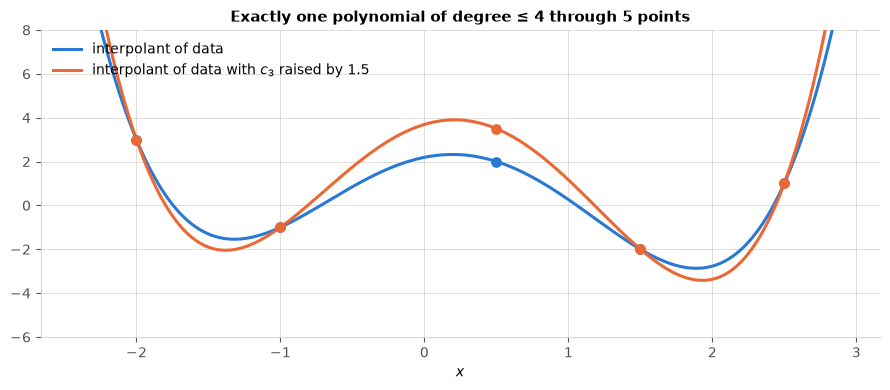

In [2]:

import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, VIOLET = "#2a78d6", "#eb6834", "#6250d6"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update({
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False, "font.size": 10})

z = np.array([-2.0, -1.0, 0.5, 1.5, 2.5])
c = np.array([3.0, -1.0, 2.0, -2.0, 1.0])
V = np.vander(z, N=len(z), increasing=True)        # rows (1, z_i, z_i^2, ...)
print("det V(z) =", round(np.linalg.det(V), 3), "(non-zero: the nodes are distinct)")

xs = np.linspace(-2.4, 2.9, 400)
fig, ax = plt.subplots(figsize=(9, 4))
for c_new, col, name in [(c, BLUE, "data"), (c + np.array([0, 0, 1.5, 0, 0]), ORANGE, "data with $c_3$ raised by 1.5")]:
    a = np.linalg.solve(V, c_new)                  # coefficients a_0, ..., a_4
    ax.plot(xs, np.polyval(a[::-1], xs), color=col, lw=2.2, label=f"interpolant of {name}")
    ax.scatter(z, c_new, color=col, s=45, zorder=3)
ax.set_ylim(-6, 8); ax.set_xlabel("$x$")
ax.legend(loc="upper left")
ax.set_title("Exactly one polynomial of degree ≤ 4 through 5 points")
plt.tight_layout(); plt.show()
